**AVIF Encoder**

Batch encode images to AVIF, plot PSNR/SSIM vs quality, and save compressed files for comparison.

This notebook mirrors the functionality of the existing `JPEG.ipynb` but uses the `pillow-avif-plugin` to write AVIF files.


[1] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Gradient_sq_gray.png -> stem=Gradient_sq_gray


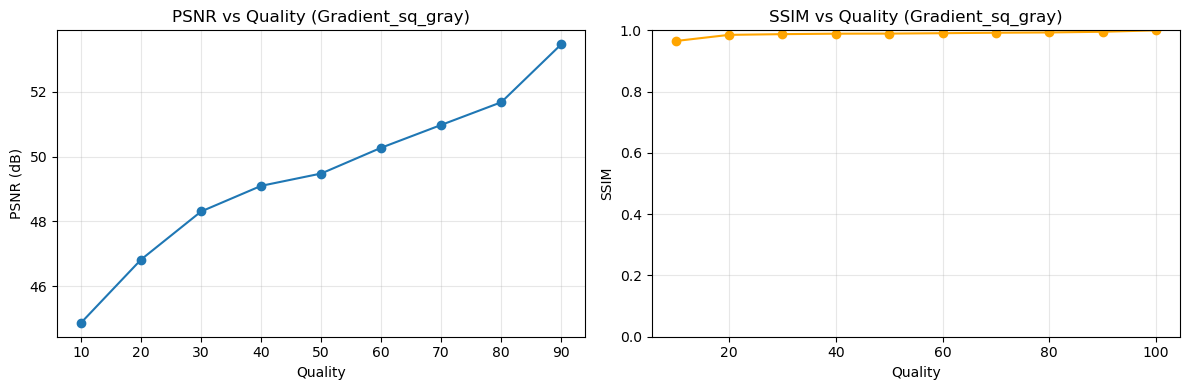

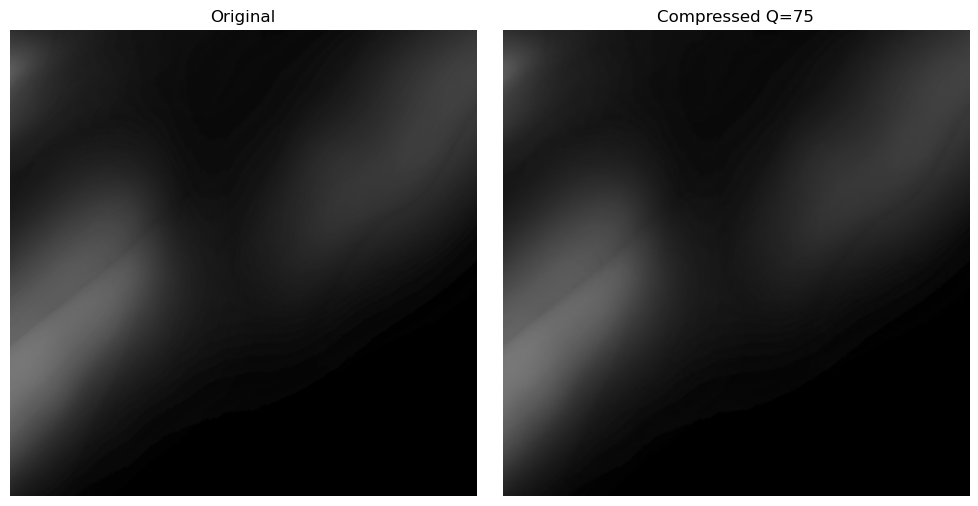

At Q=75 (display only): PSNR=51.31 dB, SSIM=0.9926

Saved compressed image: Gradient_sq_gray_Q100.avif (178.1 KB)
At Q=100: PSNR=inf dB, SSIM=1.0000

[2] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Grass_sq_gray.png -> stem=Grass_sq_gray

Saved compressed image: Gradient_sq_gray_Q100.avif (178.1 KB)
At Q=100: PSNR=inf dB, SSIM=1.0000

[2] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Grass_sq_gray.png -> stem=Grass_sq_gray


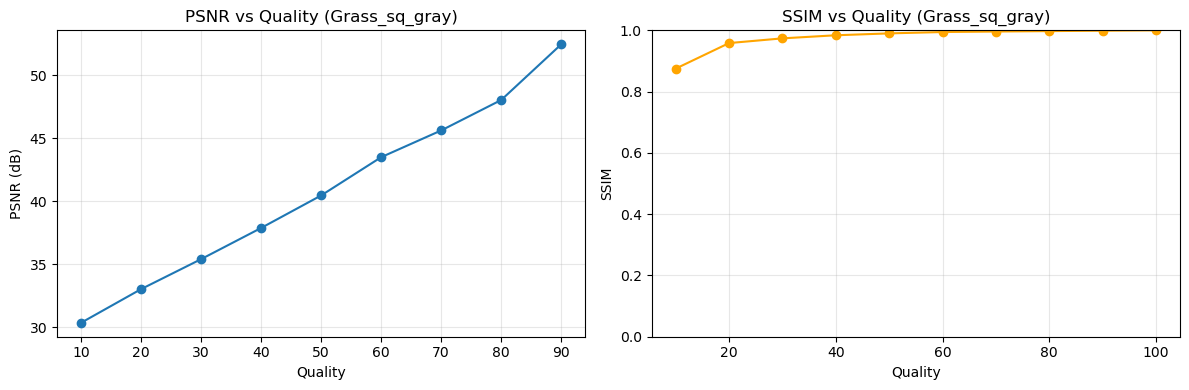

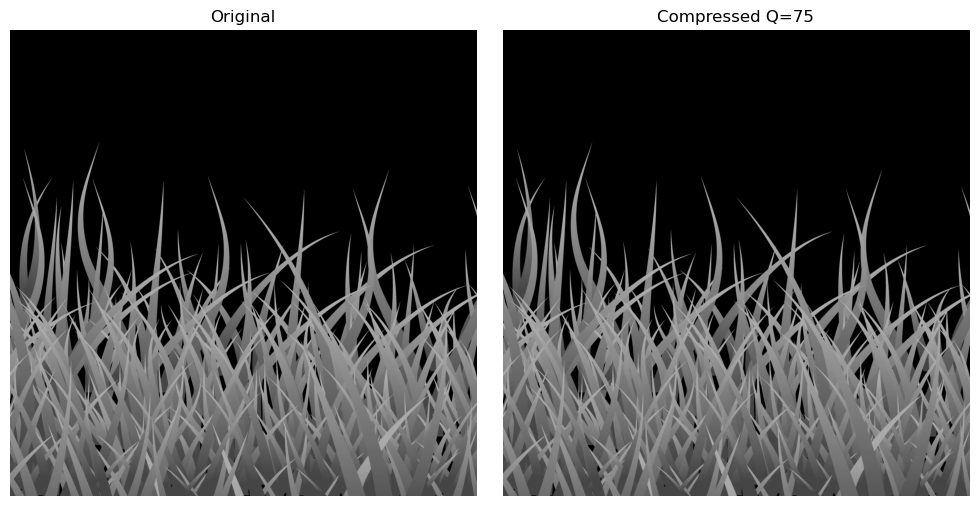

At Q=75 (display only): PSNR=46.73 dB, SSIM=0.9968

Saved compressed image: Grass_sq_gray_Q100.avif (265.2 KB)
At Q=100: PSNR=inf dB, SSIM=1.0000

[3] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Mixed_sq_gray.png -> stem=Mixed_sq_gray

Saved compressed image: Grass_sq_gray_Q100.avif (265.2 KB)
At Q=100: PSNR=inf dB, SSIM=1.0000

[3] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Mixed_sq_gray.png -> stem=Mixed_sq_gray


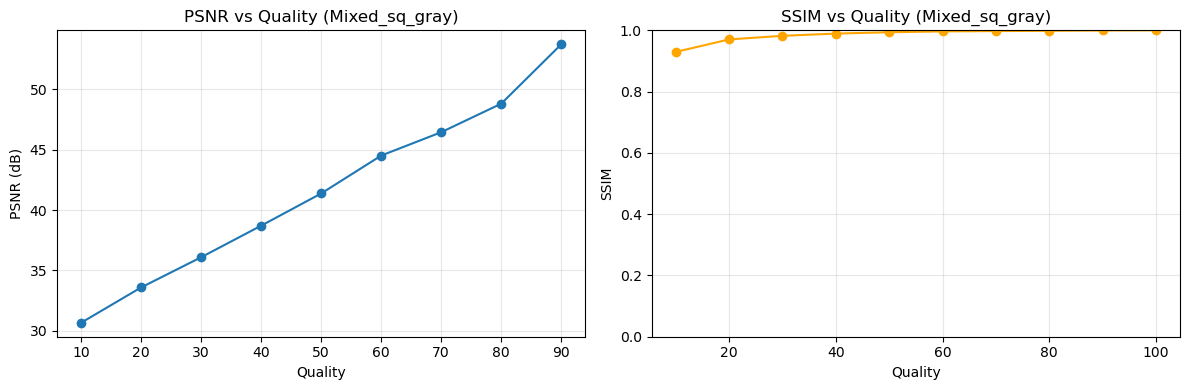

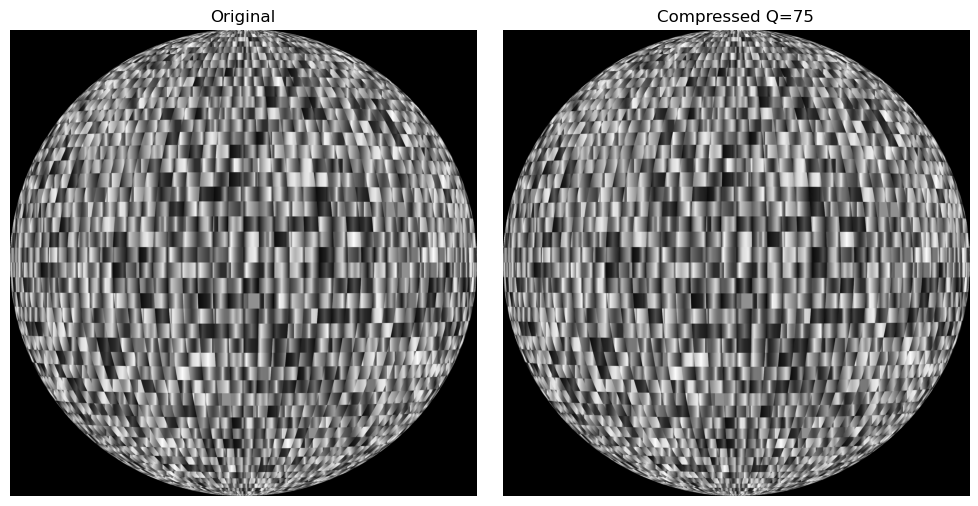

At Q=75 (display only): PSNR=47.51 dB, SSIM=0.9980

Saved compressed image: Mixed_sq_gray_Q100.avif (608.3 KB)
At Q=100: PSNR=inf dB, SSIM=1.0000

[4] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Nature_sq_gray.png -> stem=Nature_sq_gray

Saved compressed image: Mixed_sq_gray_Q100.avif (608.3 KB)
At Q=100: PSNR=inf dB, SSIM=1.0000

[4] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Nature_sq_gray.png -> stem=Nature_sq_gray


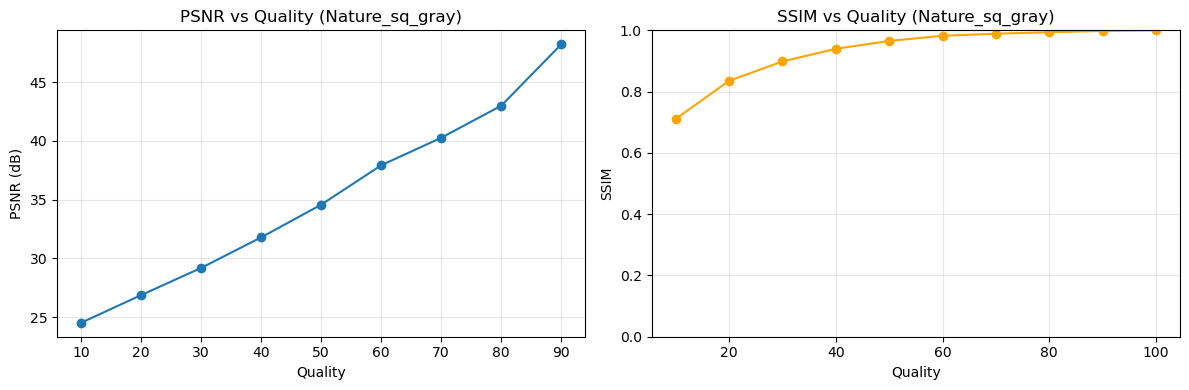

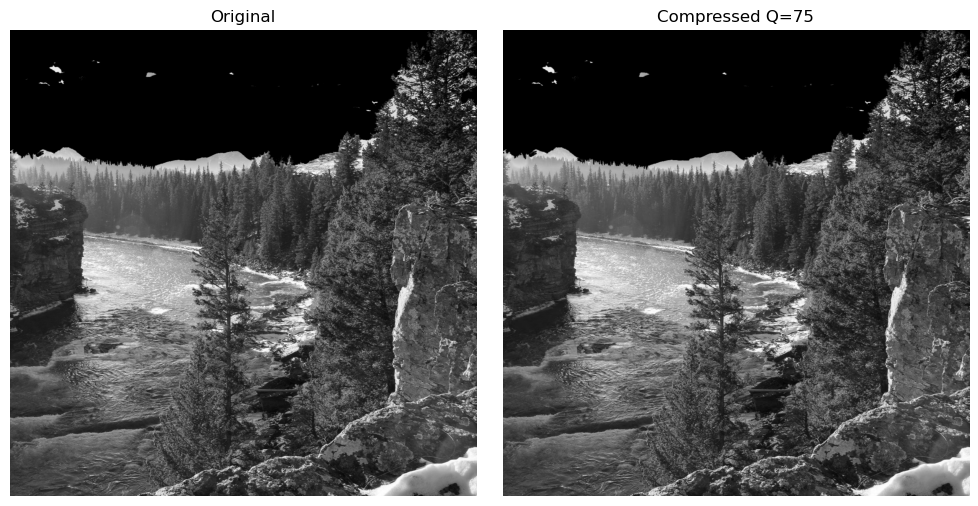

At Q=75 (display only): PSNR=41.50 dB, SSIM=0.9915

Saved compressed image: Nature_sq_gray_Q100.avif (855.7 KB)
At Q=100: PSNR=inf dB, SSIM=1.0000

[5] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\SharpEdges_sq_gray.png -> stem=SharpEdges_sq_gray

Saved compressed image: Nature_sq_gray_Q100.avif (855.7 KB)
At Q=100: PSNR=inf dB, SSIM=1.0000

[5] Processing: C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\SharpEdges_sq_gray.png -> stem=SharpEdges_sq_gray


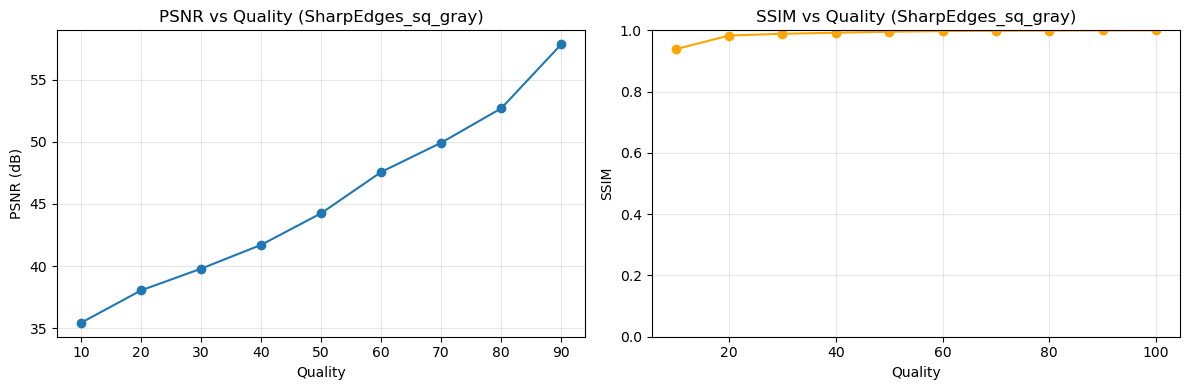

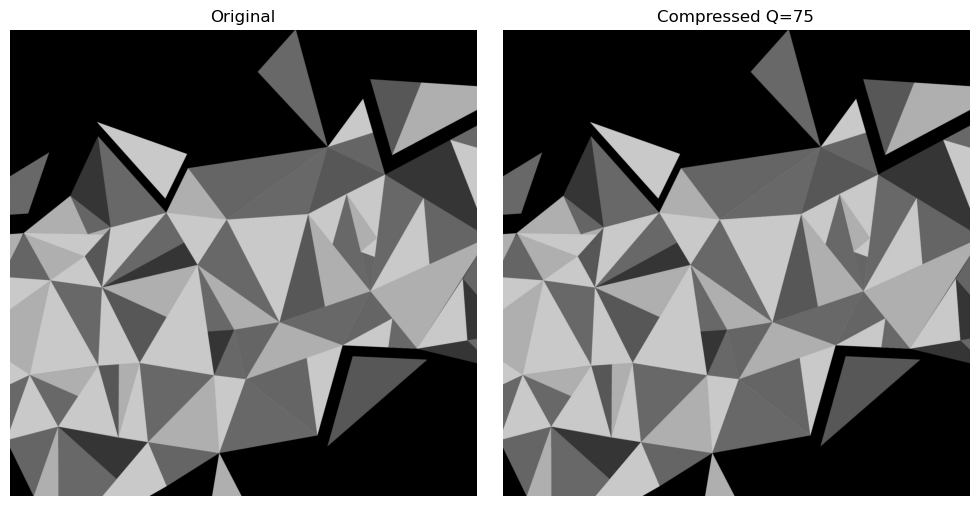

At Q=75 (display only): PSNR=51.12 dB, SSIM=0.9989

Saved compressed image: SharpEdges_sq_gray_Q100.avif (100.1 KB)
At Q=100: PSNR=inf dB, SSIM=1.0000

All done.

Saved compressed image: SharpEdges_sq_gray_Q100.avif (100.1 KB)
At Q=100: PSNR=inf dB, SSIM=1.0000

All done.


In [2]:
# Install pillow-heif which provides AVIF support (more reliable than pillow-avif-plugin)
!pip install --quiet pillow pillow-heif

# Imports
from PIL import Image
from pillow_heif import register_heif_opener
register_heif_opener()  # registers AVIF/HEIF support with Pillow
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import io
import math

# --- User: replace these with your image file paths (up to 5) ---
image_paths = [
    r"C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Gradient_sq_gray.png",
    r"C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Grass_sq_gray.png",
    r"C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Mixed_sq_gray.png",
    r"C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\Nature_sq_gray.png",
    r"C:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Images\SharpEdges_sq_gray.png"
]

# --- Helpers: PSNR / SSIM (same algorithm as in JPEG.ipynb) ---
def psnr(img1, img2, data_range=255.0):
    x = img1.astype(np.float64)
    y = img2.astype(np.float64)
    mse = np.mean((x - y) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(data_range) - 10 * np.log10(mse)

def _box_filter_same(img, w):
    if img.ndim == 2:
        img = img[..., None]
        squeeze = True
    else:
        squeeze = False
    pad = w // 2
    img_p = np.pad(img, ((pad, pad), (pad, pad), (0, 0)), mode='reflect')
    tmp = np.cumsum(img_p, axis=0)
    tmp = tmp[w:, :, :] - tmp[:-w, :, :]
    tmp2 = np.cumsum(tmp, axis=1)
    res = tmp2[:, w:, :] - tmp2[:, :-w, :]
    res = res / (w * w)
    if squeeze:
        return res[..., 0]
    return res

def ssim(img1, img2, data_range=255.0, win_size=11, K1=0.01, K2=0.03):
    x = img1.astype(np.float64)
    y = img2.astype(np.float64)
    C1 = (K1 * data_range) ** 2
    C2 = (K2 * data_range) ** 2
    mu_x = _box_filter_same(x, win_size)
    mu_y = _box_filter_same(y, win_size)
    sigma_x2 = _box_filter_same(x * x, win_size) - mu_x * mu_x
    sigma_y2 = _box_filter_same(y * y, win_size) - mu_y * mu_y
    sigma_xy = _box_filter_same(x * y, win_size) - mu_x * mu_y
    num = (2 * mu_x * mu_y + C1) * (2 * sigma_xy + C2)
    den = (mu_x * mu_x + mu_y * mu_y + C1) * (sigma_x2 + sigma_y2 + C2)
    ssim_map = num / (den + 1e-12)
    return float(np.mean(ssim_map))

# --- Processing parameters ---
qualities = list(range(10, 101, 10))  # 10..100 step 10
chosen_quality = 75  # target quality for display comparison (not saved to disk)
speed = 6  # AVIF speed/quality tradeoff (0=slow/best -> 10=fast)

# utility for human file sizes
def fmt_bytes(b):
    if b is None:
        return 'N/A'
    if b < 1024:
        return f"{b} B"
    kb = b / 1024.0
    if kb < 1024:
        return f"{kb:.1f} KB"
    mb = kb / 1024.0
    return f"{mb:.2f} MB"

# --- Run over image slots ---
for idx, p in enumerate(image_paths):
    if not p:
        continue
    path = Path(p)
    if not path.exists():
        print(f"[{idx+1}] Path not found: {p}")
        continue

    stem = path.stem
    print('\n' + '='*60)
    print(f"[{idx+1}] Processing: {path} -> stem={stem}")

    pil = Image.open(path).convert('RGB')
    orig = np.array(pil, dtype=np.uint8)

    psnrs = []
    ssims = []

    # Sweep qualities and compute metrics (compress into memory)
    for q in qualities:
        buf = io.BytesIO()
        # Save to AVIF in-memory using pillow-heif
        pil.save(buf, format='AVIF', quality=int(q))
        buf.seek(0)
        rec = np.array(Image.open(buf).convert('RGB'), dtype=np.uint8)
        psnrs.append(psnr(orig, rec))
        ssims.append(ssim(orig, rec))

    # Plot PSNR/SSIM curves
    fig, ax = plt.subplots(1,2, figsize=(12,4))
    ax[0].plot(qualities, psnrs, marker='o')
    ax[0].set_title(f'PSNR vs Quality ({stem})')
    ax[0].set_xlabel('Quality')
    ax[0].set_ylabel('PSNR (dB)')
    ax[0].grid(True, alpha=0.3)

    ax[1].plot(qualities, ssims, marker='o', color='orange')
    ax[1].set_title(f'SSIM vs Quality ({stem})')
    ax[1].set_xlabel('Quality')
    ax[1].set_ylabel('SSIM')
    ax[1].set_ylim(0, 1.0)
    ax[1].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Save highest quality compressed image
    out_file = f"{stem}_Q100.avif"
    pil.save(out_file, format='AVIF', quality=100)
    rec_100 = Image.open(out_file).convert('RGB')

    # Get size
    try:
        size_compressed = Path(out_file).stat().st_size
    except Exception:
        size_compressed = None

    # Generate Q75 compressed image for display only (not saved)
    buf = io.BytesIO()
    pil.save(buf, format='AVIF', quality=int(chosen_quality))
    buf.seek(0)
    rec = np.array(Image.open(buf).convert('RGB'), dtype=np.uint8)

    # Display side-by-side
    fig2, ax2 = plt.subplots(1,2, figsize=(10,5))
    ax2[0].imshow(orig); ax2[0].set_title('Original'); ax2[0].axis('off')
    ax2[1].imshow(rec); ax2[1].set_title(f'Compressed Q={chosen_quality}'); ax2[1].axis('off')
    plt.tight_layout()
    plt.show()

    # Print sizes and PSNR/SSIM at chosen quality (display only)
    psnr_chosen = psnr(orig, rec)
    ssim_chosen = ssim(orig, rec)
    print(f"At Q={chosen_quality} (display only): PSNR={psnr_chosen:.2f} dB, SSIM={ssim_chosen:.4f}")
    
    # Print highest quality stats
    psnr_100 = psnr(orig, np.array(rec_100, dtype=np.uint8))
    ssim_100 = ssim(orig, np.array(rec_100, dtype=np.uint8))
    print(f"\nSaved compressed image: {out_file} ({fmt_bytes(size_compressed)})")
    print(f"At Q=100: PSNR={psnr_100:.2f} dB, SSIM={ssim_100:.4f}")

print('\nAll done.')


In [3]:
# --- AVIF encoding time vs quality with PSNR/SSIM ---
import time
import pandas as pd

avif_encoding_stats = {}

for idx, p in enumerate(image_paths):
    if not p:
        continue
    path = Path(p)
    if not path.exists():
        print(f"[{idx+1}] Path not found: {p}")
        continue

    stem = path.stem
    pil = Image.open(path).convert('RGB')
    orig = np.array(pil, dtype=np.uint8)

    records = []
    for q in qualities:
        buf = io.BytesIO()
        start = time.perf_counter()
        pil.save(buf, format='AVIF', quality=int(q))
        elapsed = time.perf_counter() - start
        buf.seek(0)

        rec = np.array(Image.open(buf).convert('RGB'), dtype=np.uint8)
        psnr_val = psnr(orig, rec)
        ssim_val = ssim(orig, rec)

        records.append({
            'Quality': q,
            'Encode Time (s)': elapsed,
            'PSNR (dB)': psnr_val,
            'SSIM': ssim_val
        })

    df = pd.DataFrame(records)
    avif_encoding_stats[stem] = df
    display(
        df.style
          .format({'Encode Time (s)': '{:.4f}', 'PSNR (dB)': '{:.2f}', 'SSIM': '{:.4f}'})
          .set_caption(f'AVIF encode metrics vs quality ({stem})')
    )

,Quality,Encode Time (s),PSNR (dB),SSIM
0,10,1.2271,44.87,0.9652
1,20,1.2551,46.82,0.9852
2,30,1.0935,48.31,0.9876
3,40,1.2469,49.10,0.9890
4,50,1.1518,49.48,0.9894
5,60,1.4613,50.27,0.9906
6,70,1.3705,50.98,0.9921
7,80,1.9793,51.68,0.9931
8,90,2.1497,53.47,0.9953
9,100,1.9334,inf,1.0000


,Quality,Encode Time (s),PSNR (dB),SSIM
0,10,0.2269,30.35,0.8751
1,20,0.2233,33.02,0.9584
2,30,0.2002,35.40,0.9738
3,40,0.2424,37.88,0.9839
4,50,0.2200,40.46,0.9900
5,60,0.2610,43.50,0.9944
6,70,0.1833,45.62,0.9961
7,80,0.1666,48.04,0.9975
8,90,0.1919,52.46,0.9988
9,100,0.2835,inf,1.0000


,Quality,Encode Time (s),PSNR (dB),SSIM
0,10,0.5782,30.64,0.9295
1,20,0.7393,33.57,0.9703
2,30,0.7727,36.08,0.9821
3,40,0.7012,38.70,0.9894
4,50,0.7873,41.37,0.9937
5,60,0.8635,44.52,0.9966
6,70,0.7292,46.46,0.9976
7,80,0.7158,48.83,0.9985
8,90,0.6582,53.75,0.9995
9,100,0.9141,inf,1.0000


,Quality,Encode Time (s),PSNR (dB),SSIM
0,10,0.2742,24.52,0.7110
1,20,0.2461,26.88,0.8353
2,30,0.2369,29.19,0.8984
3,40,0.2421,31.80,0.9397
4,50,0.2854,34.58,0.9653
5,60,0.2850,37.93,0.9823
6,70,0.2863,40.27,0.9890
7,80,0.2863,43.01,0.9938
8,90,0.3551,48.23,0.9980
9,100,0.2698,inf,1.0000


,Quality,Encode Time (s),PSNR (dB),SSIM
0,10,0.1990,35.44,0.9385
1,20,0.1691,38.05,0.9831
2,30,0.1550,39.79,0.9888
3,40,0.1576,41.71,0.9922
4,50,0.1580,44.25,0.9954
5,60,0.1532,47.58,0.9976
6,70,0.1562,49.93,0.9985
7,80,0.1415,52.70,0.9992
8,90,0.1287,57.85,0.9997
9,100,0.3095,inf,1.0000
